# Linear Regression from Scratch

Building linear regression with gradient descent using only NumPy.

**Plan:**
1. Generate synthetic data from a known line
2. Train the model and check that it recovers that line
3. Explore how the learning rate affects training
4. Verify against scikit-learn

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from linreg import predict, mse_loss, compute_gradients, train

import sklearn

## 1. Synthetic data

In [3]:
SEED = 67               # keeps the random numbers the same across all runs
TRUE_SLOPE = 5          # the value the model should find for the weight
TRUE_INTERCEPT = 10     # the value the model should find for the bias
NUM_POINTS = 100        # how many data points to create
STDDEV = 2              # standard deviation of the random variable is 2 (noise)

np.random.seed(SEED)    # sets the rng start


In [4]:
x = np.random.uniform(0, 10, 100)
noise = np.random.normal(0, STDDEV, 100)
y = TRUE_SLOPE * x + TRUE_INTERCEPT + noise

print("x shape:", x.shape)
print("y shape:", y.shape)
print("first 5 x:", x[:5])
print("first 5 y:", y[:5])


x shape: (100,)
y shape: (100,)
first 5 x: [5.4585143  8.58856611 6.85892587 3.31591821 0.5999793 ]
first 5 y: [35.53463665 54.03175465 43.38036895 29.04178084 10.97080927]


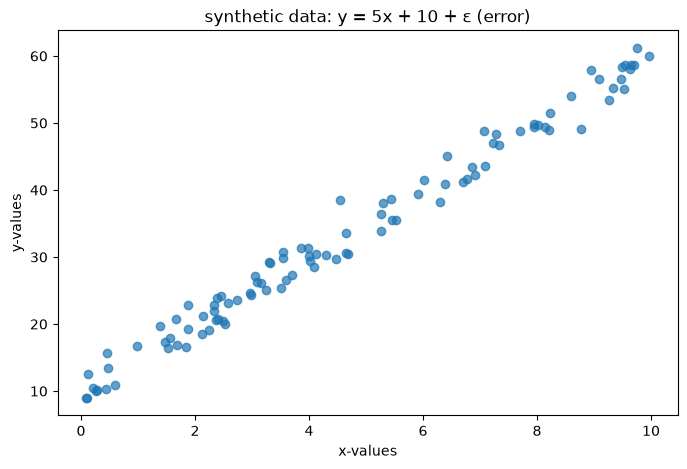

In [5]:
plt.figure(figsize=(8,5))
plt.scatter(x, y, alpha= 0.7)
plt.xlabel("x-values")
plt.ylabel("y-values")
plt.title("synthetic data: y = 5x + 10 + ε (error)")
plt.savefig("assets/synthetic_data.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Training with gradient descent

We start at $w= 0, b = 0$ and repeatedly compute the gradients w.r.t to both variables and recursively step in the opposite direction by an amount proportional to the calculated value. The gradient formulas are shown below:

$$\frac{\partial L}{\partial w} = \frac{2}{n}\sum x_i(wx_i + b - y_i) \qquad
\frac{\partial L}{\partial b} = \frac{2}{n}\sum (wx_i + b - y_i)$$

4.973199408208664 10.001429659923186


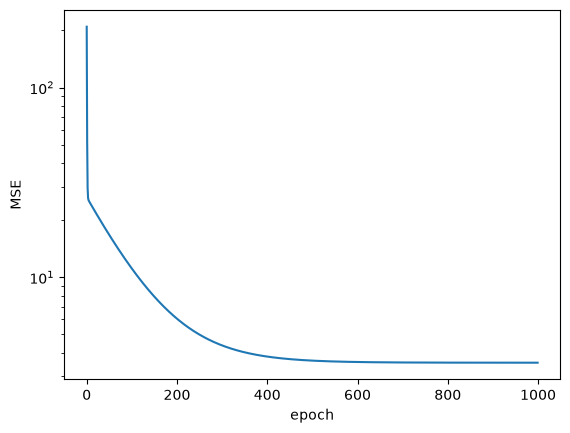

In [6]:
w, b, losses = train(x, y, lr=0.01, epochs=1000)
print(w, b)

plt.plot(losses)
plt.title("")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.yscale("log")
plt.show()


In 3D space, the MSE as a function of $w$ and $b$ forms an elliptic paraboloid, which has a single global minimum. Additionally, our gradient decreases in magnitude as we descend the surface, meaning our MSE drops quickly in the early epochs and then levels off as the steps shrink near the bottom. The curve flattens around 4 which is our noise term ($\sigma^2 = 2^2$): the error left over comes from the random noise, which no line can fit.

## 3. Learning rate experiement

Plotted a graph of MSE vs. epoch # for 5 different learning rates (0.0001, 0.001. 0.01, 0.1, 1.0), to see how step size affects the training of our model.

/Users/tv/ml-from-scratch/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/Users/tv/ml-from-scratch/01-linear-regression/linreg.py:28: RuntimeWarning: overflow encountered in square
  return np.mean((y_true-y_pred)**2)
/Users/tv/ml-from-scratch/01-linear-regression/linreg.py:66: RuntimeWarning: invalid value encountered in scalar subtract
  w -= dw * lr


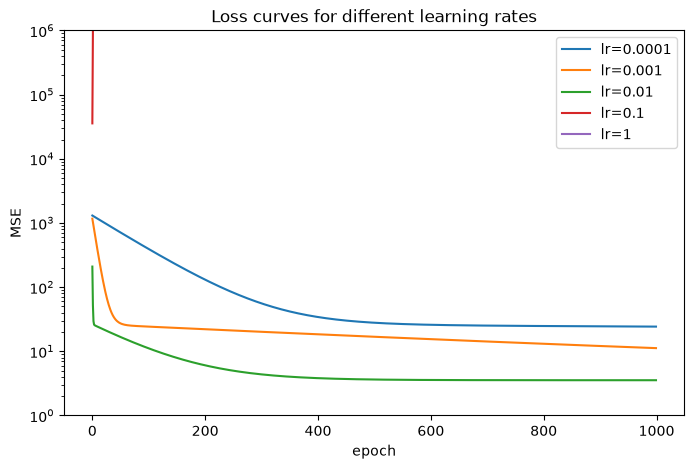

In [ ]:
plt.figure(figsize=(8,5))
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.yscale("log")
plt.ylim(1, 1e6)
learning_rates = 10**np.linspace(-4, 0, 5)
for rate in learning_rates:
    temp_w, temp_b, loss = train(x, y, lr = rate, epochs=1000)

    plt.plot(loss, label=f"lr={rate:g}")
plt.title("Loss curves for different learning rates")
plt.legend()
plt.savefig("assets/lr_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

I trained the same model with five learning rates from $10^{-4}$ to $1$ for 1000 epochs each. Some of the rates cause the model to diverge, some are too slow, and one reaches the expected MSE floor within the 1000 epochs.

**Diverged (lr = 0.1 and lr = 1):** The learning rate is too large, so each update overshoots the minimum. Each overshoot lands somewhere steeper, which makes the next update even bigger, so the loss grows until it overflows to infinity.

**Too slow (lr = 0.0001 and lr = 0.001):** The learning rate is too small, so each update barely changes the parameters. $w$ is learned fairly quickly because its gradient is scaled by $x$, but $b$ moves very slowly along the shallow direction of the loss surface. This is why the curves flatten out around 25 instead of 4: the model runs out of epochs before $b$ reaches its correct value.

**Best (lr = 0.01):** It reaches our noise floor $(\sigma^2 \approx 2^2)$ within 400 epochs and stays there for the remaining time. It makes progress fast but doesn't overshoot.

**Takeaway:** The learning rate is a tradeoff between speed and stability. If the rate is too small, training never reaches the right value, and if it's too large, it overshoots the value and diverges. For this data, the learning rate must stay below roughly 0.03 to converge, and 0.01 worked best.
